In [1]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

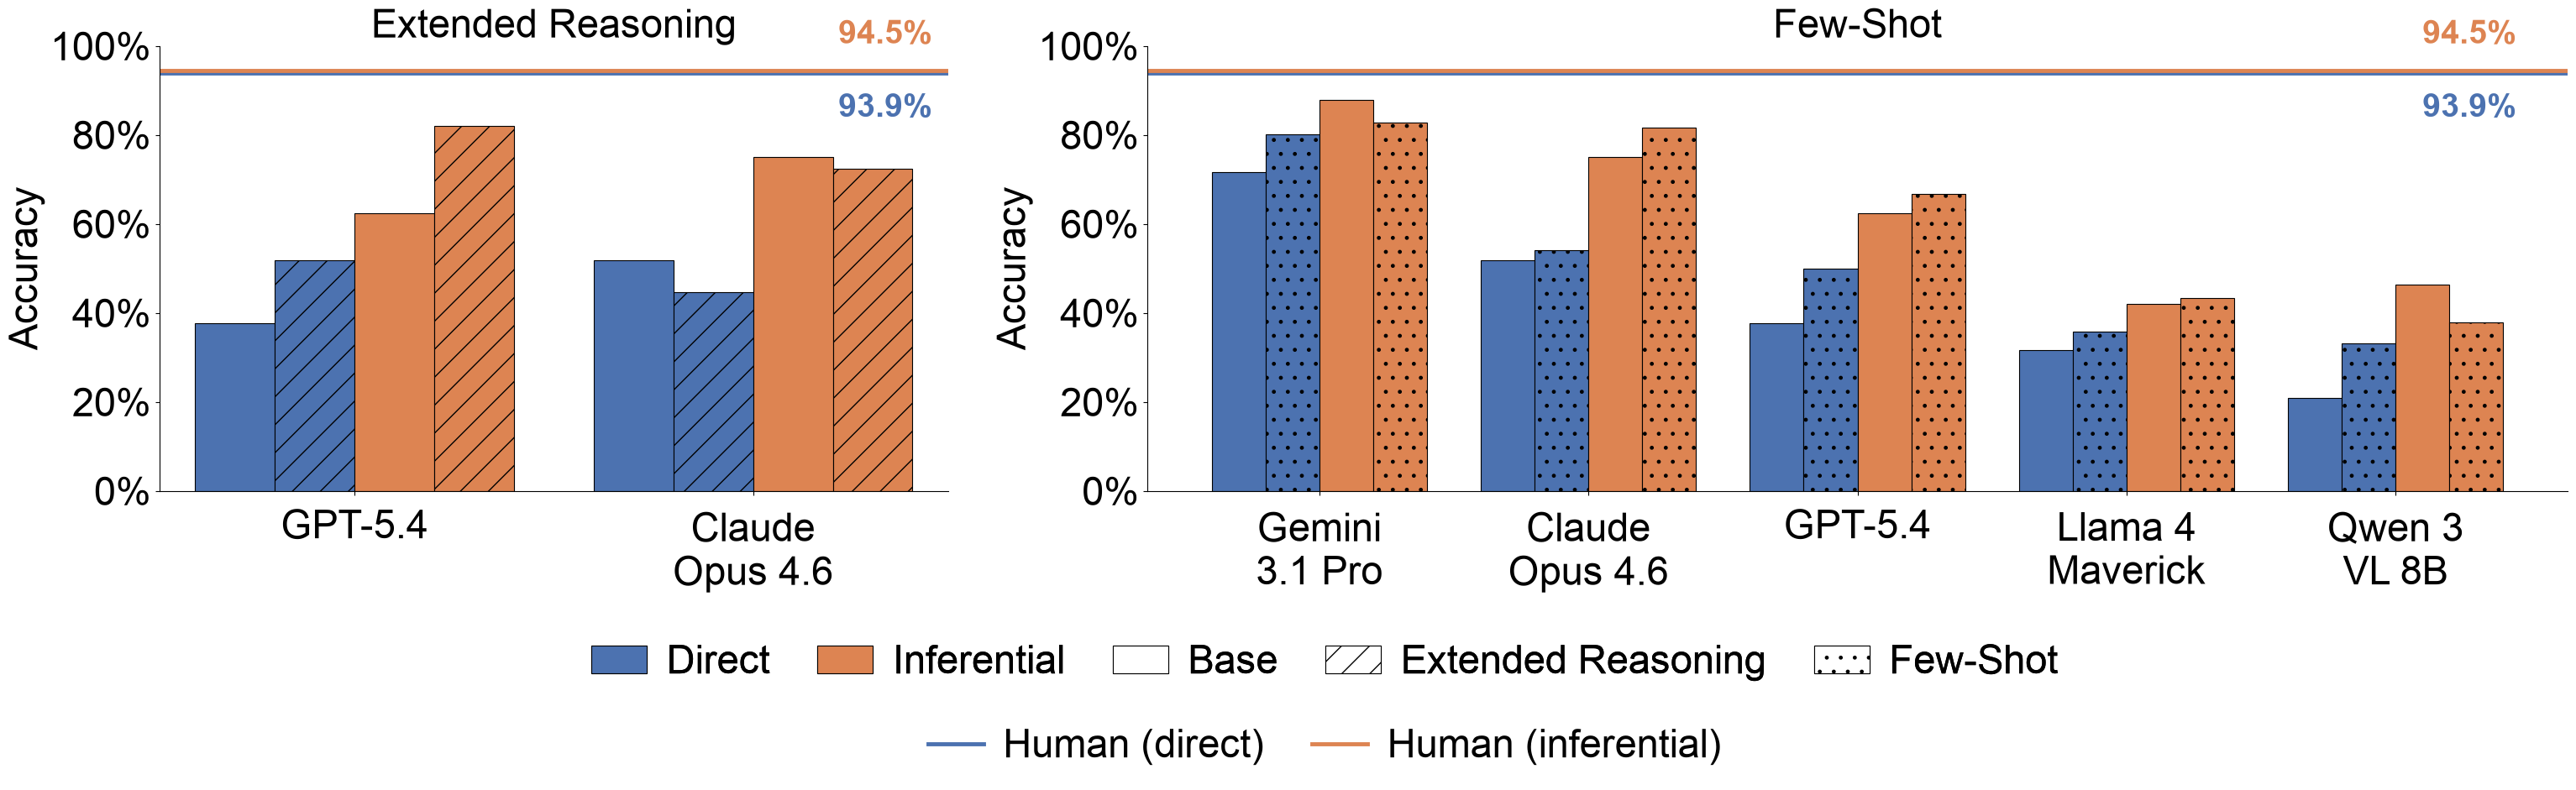

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

plt.rcParams.update({'font.family': 'Arial', 'font.size': 38})

DIRECT_COLOR = '#4C72B0'
INF_COLOR    = '#DD8452'

HATCHES = {'base': '', 'ER': '/', 'FS': '.'}

HUMAN_PHYS_SOLV = 93.9
HUMAN_INF_SOLV  = 94.5

LW = 3.5

# Either-judge accuracy from data/eval_results, data/eval_results_thinking and data/eval_results_fewshot
EXPERIMENTS = [
    {
        'title':      'Extended Reasoning',
        'models':     ['GPT-5.4', 'Claude\nOpus 4.6'],
        'direct_base': [37.6, 51.8],
        'direct_int':  [51.8, 44.7],
        'inf_base':    [62.4, 75.1],
        'inf_int':     [82.0, 72.4],
        'int_label':   'ER',
    },
    {
        'title':      'Few-Shot',
        'models':     ['Gemini\n3.1 Pro', 'Claude\nOpus 4.6', 'GPT-5.4', 'Llama 4\nMaverick', 'Qwen 3\nVL 8B'],
        'direct_base': [71.6, 51.8, 37.6, 31.6, 20.9],
        'direct_int':  [80.1, 54.1, 50.0, 35.7, 33.2],
        'inf_base':    [87.8, 75.1, 62.4, 42.0, 46.4],
        'inf_int':     [82.8, 81.7, 66.7, 43.3, 37.8],
        'int_label':   'FS',
    },
]

fig, axes = plt.subplots(1, 2, figsize=(37, 10),
                         gridspec_kw={'width_ratios': [1, 1.8], 'wspace': 0.18})

for ax, exp in zip(axes, EXPERIMENTS):
    models = exp['models']
    x = np.arange(len(models))
    w = 0.2
    lbl = exp['int_label']

    ax.bar(x - 1.5*w, exp['direct_base'], w, color=DIRECT_COLOR, hatch=HATCHES['base'], edgecolor='black', linewidth=0.8)
    ax.bar(x - 0.5*w, exp['direct_int'],  w, color=DIRECT_COLOR, hatch=HATCHES[lbl],   edgecolor='black', linewidth=0.8)
    ax.bar(x + 0.5*w, exp['inf_base'],    w, color=INF_COLOR,    hatch=HATCHES['base'], edgecolor='black', linewidth=0.8)
    ax.bar(x + 1.5*w, exp['inf_int'],     w, color=INF_COLOR,    hatch=HATCHES[lbl],   edgecolor='black', linewidth=0.8)

    x_label = len(models) - 1 + 0.45

    ax.axhline(HUMAN_PHYS_SOLV, color=DIRECT_COLOR, linestyle='-', linewidth=LW)
    ax.text(x_label, HUMAN_PHYS_SOLV - 4.5, f'{HUMAN_PHYS_SOLV}%',
            color=DIRECT_COLOR, ha='right', va='top', fontsize=28, fontweight='bold')

    ax.axhline(HUMAN_INF_SOLV, color=INF_COLOR, linestyle='-', linewidth=LW)
    ax.text(x_label, HUMAN_INF_SOLV + 4.5, f'{HUMAN_INF_SOLV}%',
            color=INF_COLOR, ha='right', va='bottom', fontsize=28, fontweight='bold')

    ax.set_title(exp['title'], fontsize=34)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=0, ha='center', fontsize=34)
    ax.set_ylim(0, 100)
    ax.set_ylabel('Accuracy', fontsize=34)
    ax.tick_params(axis='x', labelsize=34, pad=12)
    ax.tick_params(axis='y', labelsize=34)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# --- Legend row 1: color | color | pattern | pattern | pattern ---
SWATCH = 'white'
bar_handles = [
    mpatches.Patch(facecolor=DIRECT_COLOR, edgecolor='black', linewidth=0.8, label='Direct'),
    mpatches.Patch(facecolor=INF_COLOR,    edgecolor='black', linewidth=0.8, label='Inferential'),
    mpatches.Patch(facecolor=SWATCH, edgecolor='black', linewidth=0.8, hatch='',  label='Base'),
    mpatches.Patch(facecolor=SWATCH, edgecolor='black', linewidth=0.8, hatch='/', label='Extended Reasoning'),
    mpatches.Patch(facecolor=SWATCH, edgecolor='black', linewidth=0.8, hatch='.', label='Few-Shot'),
]
bar_labels = [h.get_label() for h in bar_handles]

# --- Legend row 2: colored solid lines ---
line_handles = [
    mlines.Line2D([], [], color=DIRECT_COLOR, linestyle='-', linewidth=LW),
    mlines.Line2D([], [], color=INF_COLOR,    linestyle='-', linewidth=LW),
]
line_labels = ['Human (direct)', 'Human (inferential)']

plt.subplots_adjust(bottom=0.35)

leg1 = fig.legend(bar_handles, bar_labels,
                  loc='lower center', ncol=len(bar_handles),
                  bbox_to_anchor=(0.5, 0.08), frameon=False, fontsize=34,
                  columnspacing=1.2, handlelength=1.4, handletextpad=0.5)
fig.legend(line_handles, line_labels,
           loc='lower center', ncol=len(line_handles),
           bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=34,
           columnspacing=1.2, handlelength=1.4, handletextpad=0.5)
fig.add_artist(leg1)

plt.savefig('data/figures/accuracy_improvements.pdf', bbox_inches='tight')
plt.show()